# Database basics with SQLite

## Use of AI: can be used, but must be reported.
## AI shall not be used to complete the whole assignment.

Use a library SQLite, which is a built-in library in Python for working with SQLite databases

In [69]:
import sqlite3

## Create table

In [70]:
# Connect to the SQLite database (or create a new one)
conn = sqlite3.connect('Products.db')

In [71]:
# Create a cursor object to interact with the database
cursor = conn.cursor()

In [72]:
# Define the SQL statement to create a table
create_table_sql = '''
CREATE TABLE IF NOT EXISTS products (
    id INTEGER PRIMARY KEY,
    product TEXT,
    value INTEGER);
'''


In [73]:
# Execute the SQL statement to create the table
cursor.execute(create_table_sql)

In [74]:
# Commit the changes and close the connection
conn.commit()
conn.close()

## Insert data to database

In [75]:
# Connect to the database
conn = sqlite3.connect('Products.db')
# Create a cursor object to interact with the database
cursor = conn.cursor()

In [76]:
# Define the SQL statement to insert data into the table
insert_data_sql = '''
INSERT INTO products (id, product, value)
VALUES (?, ?, ?)
'''

In [77]:
# Define the data to be inserted
data_to_insert = (1, 'Violin', 450)
# Execute the SQL statement to insert data
cursor.execute(insert_data_sql, data_to_insert)

In [78]:
data_to_insert = (2, 'Guitar', 500)
cursor.execute(insert_data_sql, data_to_insert)
data_to_insert = (3, 'Harp', 700)
cursor.execute(insert_data_sql, data_to_insert)
data_to_insert = (4, 'Flute', 10)
cursor.execute(insert_data_sql, data_to_insert)

In [79]:
# Commit the changes and close the connection
conn.commit()
conn.close()

## Insert multiple data to database

### Task: find how you can insert multiple instruments in same statement.
- Guidance e.g. in: https://pynative.com/python-sqlite-insert-into-table/
- Hint: executemany()

Add your code so that all the new_instruments are added to the database (using executemany()).

In [80]:
# YOUR CODE HERE
conn = sqlite3.connect('Products.db')
cursor = conn.cursor()

# DO NOT CHANGE THIS
# Define multiple records as a list of tuples
new_instruments = [
    (5, 'Drums', 800),
    (6, 'Piano', 1500),
    (7, 'Saxophone', 650),
    (8, 'Didgeridoo', 300),
    (9, 'Oboe', 600)
]

# YOUR CODE HERE
# Note: alway use try / finally to clean up resources, even if an error occurs
try:
    # Use executemany to insert multiple records at once
    cursor.executemany(insert_data_sql, new_instruments)
    # Commit the changes
    conn.commit()
except sqlite3.Error as e:
    print(f"An error occurred: {e}")
finally:
    # Close the connection
    conn.close() 

## Search from database

In [81]:
# Connect to the database
conn = sqlite3.connect('Products.db')
# Create a cursor object to interact with the database
cursor = conn.cursor()

In [82]:
# Define a search query (SQL SELECT statement)
search_query = "SELECT * FROM products;"

In [83]:
# Execute the search query with the parameter
cursor.execute(search_query)

In [84]:
# Fetch all matching rows
result = cursor.fetchall()

In [85]:
print(result)

[(1, 'Violin', 450), (2, 'Guitar', 500), (3, 'Harp', 700), (4, 'Flute', 10), (5, 'Drums', 800), (6, 'Piano', 1500), (7, 'Saxophone', 650), (8, 'Didgeridoo', 300), (9, 'Oboe', 600)]


In [86]:
# Define a search query based on condition
search_query = "SELECT * FROM products WHERE product = 'Violin';"
cursor.execute(search_query)
result = cursor.fetchall()
print(result)

[(1, 'Violin', 450)]


In [87]:
# Define a search query based on condition
search_query = "SELECT * FROM products WHERE value > 1000;"
cursor.execute(search_query)
result = cursor.fetchall()
print(result)

[(6, 'Piano', 1500)]


In [88]:
# Arrange results in order DESC
search_query = "SELECT * FROM products WHERE value > 700 ORDER BY product DESC;"
cursor.execute(search_query)
result = cursor.fetchall()
print(result)

[(6, 'Piano', 1500), (5, 'Drums', 800)]


In [89]:
# Arrange results in order ASC
search_query = "SELECT * FROM products ORDER BY product ASC;"
cursor.execute(search_query)
result = cursor.fetchall()
print(result)

[(8, 'Didgeridoo', 300), (5, 'Drums', 800), (4, 'Flute', 10), (2, 'Guitar', 500), (3, 'Harp', 700), (9, 'Oboe', 600), (6, 'Piano', 1500), (7, 'Saxophone', 650), (1, 'Violin', 450)]


In [90]:
# Close the cursor and connection
cursor.close()
conn.close()


## Update value in database

In [91]:
conn = sqlite3.connect('Products.db')
cursor = conn.cursor()

In [92]:
update_query = '''
UPDATE products
SET product = 'Guitar', value = 2000
WHERE product = 'Guitar';
'''

In [93]:
cursor.execute(update_query)
conn.commit()

In [94]:
# Check value
search_query = "SELECT * FROM products ORDER BY product ASC;"
cursor.execute(search_query)
result = cursor.fetchall()
print(result)

[(8, 'Didgeridoo', 300), (5, 'Drums', 800), (4, 'Flute', 10), (2, 'Guitar', 2000), (3, 'Harp', 700), (9, 'Oboe', 600), (6, 'Piano', 1500), (7, 'Saxophone', 650), (1, 'Violin', 450)]


In [95]:
# Close the cursor and connection
cursor.close()
conn.close()

## Remove rows from database

In [96]:
conn = sqlite3.connect('Products.db')
cursor = conn.cursor()
# Define your delete query with the WHERE condition
delete_query = '''
DELETE FROM products
WHERE id = 5 OR id = 6 OR id=7;
'''


In [97]:
# Execute the delete query
cursor.execute(delete_query)
# Check value
search_query = "SELECT * FROM products ORDER BY product DESC;"
cursor.execute(search_query)
result = cursor.fetchall()
print(result)

[(1, 'Violin', 450), (9, 'Oboe', 600), (3, 'Harp', 700), (2, 'Guitar', 2000), (4, 'Flute', 10), (8, 'Didgeridoo', 300)]


In [98]:
# Close the cursor and connection
cursor.close()
conn.close()

## Remove the whole table from the database

In [99]:
conn = sqlite3.connect('Products.db')
cursor = conn.cursor()
# remove complete table
delete_query = '''
DROP TABLE products;
'''
cursor.execute(delete_query)
conn.commit()

##### Check that the table is removed
- NOTE: You should get Error "OperationalError: no such table: products" if table is removed if you try to search from it.

In [100]:
search_query = "SELECT * FROM products;"
cursor.execute(search_query)
result = cursor.fetchall()
print(result)

OperationalError: no such table: products

In [ ]:
# Close the cursor and connection
cursor.close()
conn.close()

## Tasks

##### 1. Use CSV file you find in this assigment (2021.csv)
##### 2. Read the data in Pandas DataFrame and check the usual things about the data.

In [101]:
# YOUR CODE HERE
# Read the data from the CSV file into a pandas DataFrame
import pandas as pd
df = pd.read_csv('2021.csv')
df.head()

,Country name,Regional indicator,Ladder score,Standard error of ladder score,upperwhisker,lowerwhisker,Logged GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Ladder score in Dystopia,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual
0,Finland,Western Europe,7.842,0.032,7.904,7.780,10.775,0.954,72.0,0.949,-0.098,0.186,2.43,1.446,1.106,0.741,0.691,0.124,0.481,3.253
1,Denmark,Western Europe,7.620,0.035,7.687,7.552,10.933,0.954,72.7,0.946,0.030,0.179,2.43,1.502,1.108,0.763,0.686,0.208,0.485,2.868
2,Switzerland,Western Europe,7.571,0.036,7.643,7.500,11.117,0.942,74.4,0.919,0.025,0.292,2.43,1.566,1.079,0.816,0.653,0.204,0.413,2.839
3,Iceland,Western Europe,7.554,0.059,7.670,7.438,10.878,0.983,73.0,0.955,0.160,0.673,2.43,1.482,1.172,0.772,0.698,0.293,0.170,2.967
4,Netherlands,Western Europe,7.464,0.027,7.518,7.410,10.932,0.942,72.4,0.913,0.175,0.338,2.43,1.501,1.079,0.753,0.647,0.302,0.384,2.798


In [102]:
# YOUR CODE HERE
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 149 entries, 0 to 148
Data columns (total 20 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Country name                                149 non-null    str    
 1   Regional indicator                          149 non-null    str    
 2   Ladder score                                149 non-null    float64
 3   Standard error of ladder score              149 non-null    float64
 4   upperwhisker                                149 non-null    float64
 5   lowerwhisker                                149 non-null    float64
 6   Logged GDP per capita                       149 non-null    float64
 7   Social support                              149 non-null    float64
 8   Healthy life expectancy                     149 non-null    float64
 9   Freedom to make life choices                149 non-null    float64
 10  Generosity               

In [103]:
# Add more code cells whenever necessary
df.describe()

,Ladder score,Standard error of ladder score,upperwhisker,lowerwhisker,Logged GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Ladder score in Dystopia,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual
count,149.000000,149.000000,149.000000,149.000000,149.000000,149.000000,149.000000,149.000000,149.000000,149.000000,149.00,149.000000,149.000000,149.000000,149.000000,149.000000,149.000000,149.000000
mean,5.532839,0.058752,5.648007,5.417631,9.432208,0.814745,64.992799,0.791597,-0.015134,0.727450,2.43,0.977161,0.793315,0.520161,0.498711,0.178047,0.135141,2.430329
std,1.073924,0.022001,1.054330,1.094879,1.158601,0.114889,6.762043,0.113332,0.150657,0.179226,0.00,0.404740,0.258871,0.213019,0.137888,0.098270,0.114361,0.537645
min,2.523000,0.026000,2.596000,2.449000,6.635000,0.463000,48.478000,0.382000,-0.288000,0.082000,2.43,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.648000
25%,4.852000,0.043000,4.991000,4.706000,8.541000,0.750000,59.802000,0.718000,-0.126000,0.667000,2.43,0.666000,0.647000,0.357000,0.409000,0.105000,0.060000,2.138000
50%,5.534000,0.054000,5.625000,5.413000,9.569000,0.832000,66.603000,0.804000,-0.036000,0.781000,2.43,1.025000,0.832000,0.571000,0.514000,0.164000,0.101000,2.509000
75%,6.255000,0.070000,6.344000,6.128000,10.421000,0.905000,69.600000,0.877000,0.079000,0.845000,2.43,1.323000,0.996000,0.665000,0.603000,0.239000,0.174000,2.794000
max,7.842000,0.173000,7.904000,7.780000,11.647000,0.983000,76.953000,0.970000,0.542000,0.939000,2.43,1.751000,1.172000,0.897000,0.716000,0.541000,0.547000,3.482000


##### 3. Create then SQL database 'Happy.db' and table 'happy2021' that contain following data:
- id SERIAL PRIMARY KEY
- country TEXT
- region TEXT
- lscore REAL
- hlife REAL

In [104]:
# YOUR CODE HERE
conn = sqlite3.connect('Happy.db')
cursor = conn.cursor()
try:
    # Create a new table
    create_table_sql = '''
    CREATE TABLE IF NOT EXISTS happy2021 (
        id SERIAL PRIMARY KEY,
        country TEXT,
        region TEXT,
        lscore REAL,
        hlife REAL);
    '''
    cursor.execute(create_table_sql)
except sqlite3.Error as e:
    print(f"An error occurred: {e}") 
finally:
    conn.close()

##### 4. Store data from Pandas DataFrame to the SQL table 'happy2021' following way:
- 'Country name' to 'country'
- 'Regional indicator' to 'region'
- 'Ladder score' to 'lscore'
- 'Healthy life expectancy' to 'hlife'

In [105]:
# YOUR CODE HERE

# Simple way to do that: rename df columns, remove colunns we do not need,
# and then use the to_sql method to insert the data into the database.
# Rename columns to match the database table
df.rename(columns={'Country name': 'country', 'Regional indicator':
                   'region', 'Ladder score': 'lscore',
                   'Healthy life expectancy': 'hlife'}, inplace=True)
df = (
    df[['country', 'region', 'lscore', 'hlife']]
    .sort_values('country')
    .reset_index(drop=True)
)

# Note: use the shared connection to the database
# to insert the data into the table
conn = sqlite3.connect('Happy.db')

# now use to_sql method to insert the data into the database
try:
    df.to_sql('happy2021', conn, if_exists='replace', index=False)
except Exception as e:
    print(f"Unable to write data to database: {e}")  
# Verify the data in the database by querying the table and
# displaying the results

cursor = conn.cursor()
try:
    print("Data in the happy2021 table:")
    cursor.execute("SELECT * FROM happy2021")
    rows = cursor.fetchall()
    for row in rows:
        print(row)
except sqlite3.Error as e:
    print(f"An error occurred: {e}")
finally:
    conn.close()

Data in the happy2021 table:
('Afghanistan', 'South Asia', 2.523, 52.493)
('Albania', 'Central and Eastern Europe', 5.117, 68.999)
('Algeria', 'Middle East and North Africa', 4.887, 66.005)
('Argentina', 'Latin America and Caribbean', 5.929, 69.0)
('Armenia', 'Commonwealth of Independent States', 5.283, 67.055)
('Australia', 'North America and ANZ', 7.183, 73.9)
('Austria', 'Western Europe', 7.268, 73.3)
('Azerbaijan', 'Commonwealth of Independent States', 5.171, 65.656)
('Bahrain', 'Middle East and North Africa', 6.647, 69.495)
('Bangladesh', 'South Asia', 5.025, 64.8)
('Belarus', 'Commonwealth of Independent States', 5.534, 66.253)
('Belgium', 'Western Europe', 6.834, 72.199)
('Benin', 'Sub-Saharan Africa', 5.045, 54.713)
('Bolivia', 'Latin America and Caribbean', 5.716, 63.901)
('Bosnia and Herzegovina', 'Central and Eastern Europe', 5.813, 68.098)
('Botswana', 'Sub-Saharan Africa', 3.467, 59.269)
('Brazil', 'Latin America and Caribbean', 6.33, 66.601)
('Bulgaria', 'Central and East

##### 5. Read data from the database where hlife (Healthy life expectancy) is higher than 74
and show the results in alphapetical order based on country

In [106]:
# YOUR CODE HERE
conn = sqlite3.connect('Happy.db')
cursor = conn.cursor()
try:
    sql_query = '''
    SELECT * FROM happy2021 WHERE hlife > 74;
    '''
    cursor.execute(sql_query)
    for row in cursor.fetchall():
        print(row)
except sqlite3.Error as e:
    print(f"An error occurred: {e}")  
finally:
    conn.close()

('Hong Kong S.A.R. of China', 'East Asia', 5.477, 76.82)
('Japan', 'East Asia', 5.94, 75.1)
('Singapore', 'Southeast Asia', 6.377, 76.953)
('Spain', 'Western Europe', 6.491, 74.7)
('Switzerland', 'Western Europe', 7.571, 74.4)


##### 6. Compare the result with original data you have in Pandas DataFrame with the same condition

In [107]:
# YOUR CODE HERE
# Display the data with same condition from the Pandas DataFrame
filtered_df = df[df['hlife'] > 74]
print(filtered_df)

# We ca see the same result, with 5 records, from both the database and the Pandas DataFrame.

                       country          region  lscore   hlife
52   Hong Kong S.A.R. of China       East Asia   5.477  76.820
64                       Japan       East Asia   5.940  75.100
119                  Singapore  Southeast Asia   6.377  76.953
124                      Spain  Western Europe   6.491  74.700
128                Switzerland  Western Europe   7.571  74.400


7. Aggregation and Grouping: Write an SQL query to find the average ladder score (lscore) and the total count of countries for each region (region).
- Print out the result so that the output print is easily readable.
- If you struggle with the SQL query, feel free to use AI. As long as you understand, what AI produces you.

In [108]:
# YOUR CODE HERE

conn = sqlite3.connect('Happy.db')
cursor = conn.cursor()
try:
    sql_query = '''
    SELECT region, AVG(hlife), COUNT(*) FROM happy2021 
        GROUP BY region 
        ORDER BY region;
    '''
    cursor.execute(sql_query)
    print("Average Healthy Life Expectancy by Region:\r\n")
    for row in cursor.fetchall():
        print(f"{row[0]}: Average Ladder Score = {row[1]:.2f}, Count = {row[2]}")
except sqlite3.Error as e:
    print(f"An error occurred: {e}")  
finally:
    conn.close()

Average Healthy Life Expectancy by Region:

Central and Eastern Europe: Average Ladder Score = 68.34, Count = 17
Commonwealth of Independent States: Average Ladder Score = 65.01, Count = 12
East Asia: Average Ladder Score = 71.25, Count = 6
Latin America and Caribbean: Average Ladder Score = 67.08, Count = 20
Middle East and North Africa: Average Ladder Score = 65.61, Count = 17
North America and ANZ: Average Ladder Score = 72.33, Count = 4
South Asia: Average Ladder Score = 62.68, Count = 7
Southeast Asia: Average Ladder Score = 64.89, Count = 9
Sub-Saharan Africa: Average Ladder Score = 55.89, Count = 36
Western Europe: Average Ladder Score = 73.03, Count = 21


8. Perform the identical grouping and aggregation on your original DataFrame df and verify that the calculated averages and counts match perfectly with your SQL output.
- Hint: try to construct the code piece by piece and check frequently, what did you get.
- Hint: use groupby(), agg() and sort_values()

In [109]:
# YOUR CODE HERE
region_df = df.groupby('region')['hlife'].agg(
    ['mean', 'count']
    ).sort_values('region')
region_df.style.format({'mean': '{:.2f}', 'count': '{:d}'})

# We will have the same result, with 6 records, from both the database and the Pandas DataFrame.

,mean,count
region,,
Central and Eastern Europe,68.34,17
Commonwealth of Independent States,65.01,12
East Asia,71.25,6
Latin America and Caribbean,67.08,20
Middle East and North Africa,65.61,17
North America and ANZ,72.33,4
South Asia,62.68,7
Southeast Asia,64.89,9
Sub-Saharan Africa,55.89,36


9. Exporting queries back to Pandas & Plotting: Write an SQL query to retrieve the top 10 happiest countries (highest lscore) from Happy.db. Use pd.read_sql_query() to load these specific 10 records directly from the database into a new DataFrame, and plot a quick horizontal bar chart of their ladder scores.

Top 10 happiest countries:

Finland with score = 7.84
Denmark with score = 7.62
Switzerland with score = 7.57
Iceland with score = 7.55
Netherlands with score = 7.46
Norway with score = 7.39
Sweden with score = 7.36
Luxembourg with score = 7.32
New Zealand with score = 7.28
Austria with score = 7.27

DataFrame of Top 10 happiest countries:

       country  lscore
0      Finland   7.842
1      Denmark   7.620
2  Switzerland   7.571
3      Iceland   7.554
4  Netherlands   7.464
5       Norway   7.392
6       Sweden   7.363
7   Luxembourg   7.324
8  New Zealand   7.277
9      Austria   7.268


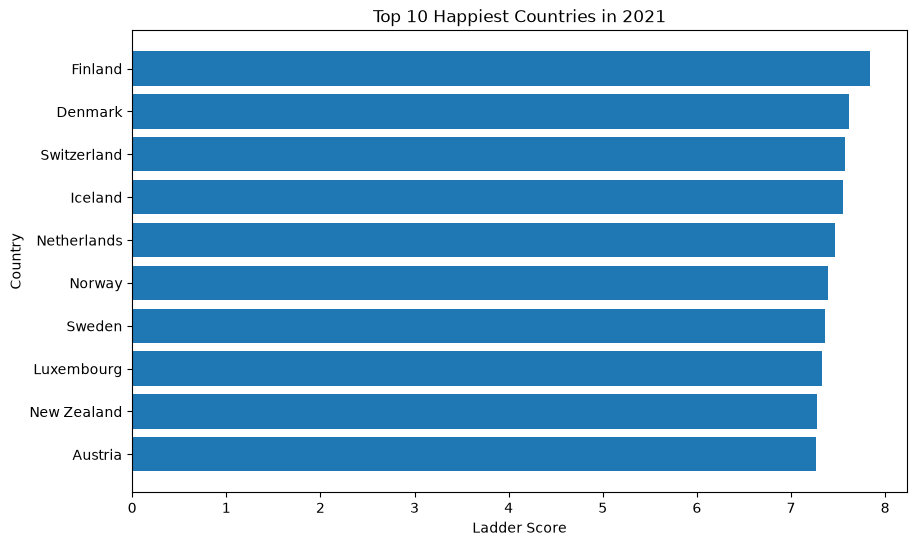

In [110]:
# YOUR CODE HERE

import matplotlib.pyplot as plt

# Export data from the database to dataframe back, with filter condition
# then load these data into the new data frame

conn = sqlite3.connect('Happy.db')
cursor = conn.cursor()
try:
    sql_query = '''
    SELECT country, lscore FROM happy2021 
        ORDER BY lscore DESC
        LIMIT 10;
    '''
    cursor.execute(sql_query)
    # Query the top 10 happiest countries based on ladder score
    print("Top 10 happiest countries:\r\n")
    for row in cursor.fetchall():
        print(f"{row[0]} with score = {row[1]:.2f}")
    # Create new DataFrame from the query result
    top_happy_countries_df = pd.read_sql_query(sql_query, conn)
    print("\nDataFrame of Top 10 happiest countries:\r\n")
    print(top_happy_countries_df)

    # We can see, the results are the same, with 10 records,
    # from both the database and the Pandas DataFrame.

    # Now plot the chart horizontal bar chart

    plt.figure(figsize=(10, 6))
    plt.barh(top_happy_countries_df['country'], top_happy_countries_df['lscore'])
    plt.xlabel('Ladder Score')
    plt.ylabel('Country')
    plt.title('Top 10 Happiest Countries in 2021')
    plt.gca().invert_yaxis()  # Invert y-axis to have the highest score
    plt.show()

except sqlite3.Error as e:
    print(f"An error occurred: {e}")  
finally:
    conn.close()


## Task: AI statement (mandatory)

- I use AI to correct English grammar errors, programming syntax errors



## Task return

File > Save and Export Notebook As > HTML

Then take a look the produced HTML that it looks ok and readable

Return to Itslearning, only the html document is returned, *not* the .ipynb